# 01 - Data Preparation

**IT469 (King Saud University) - NER on Human-Written vs. LLM-Generated News**

## Purpose

This notebook is step 1 of the project pipeline (see `CLAUDE.md` / the repo README for the full picture).
It takes the raw **LLM-generated News dataset** [1] and turns it into clean, matched, sentence-tokenized
human/LLM text ready for weak-supervision annotation in `03_silver_labeling.ipynb`, which will run the
RoBERTa-large annotator fine-tuned on CoNLL-2003 [2] in `02_annotator_selection.ipynb` over every sentence
produced here.

## Dataset

The LLM-generated News dataset [1] has 3,000 news articles from nine outlets (AP, Reuters, The Guardian,
CBS, NBC, ABC, Al Jazeera, CNN, American Press) across six topics, each paired with LLM-generated versions.
We use `chatgpt.csv` (GPT-3.5), specifically:

- **`main`** — the original, human-written article.
- **`summary_expanded`** — GPT-3.5 wrote a full article from a summary of the original.

These two columns are **matched pairs**: the same story, written once by a journalist and once by an LLM
from a summary of it. That pairing is what makes a controlled human-vs-LLM NER comparison possible later.

## What we know about the raw data (measured in advance, used for sanity checks below)

- 3,000 rows; columns: `agency, title, main, words, topic, rephrase, expanded, summary, summary_expanded`.
- `summary_expanded` is missing in 46 rows.
- Articles repeat: exact copies, same-title "snapshots" saved multiple times (e.g. a live-blog saved
  several times), and near-identical wire stories republished by two outlets under different titles.
- **Encoding error in `main` only**: Windows-1252 punctuation got stored as C1 control characters
  (U+0080-U+009F) -- e.g. `"Dylan\x92s"` for `"Dylan's"`, `\x93`/`\x94` for curly quotes, `\x97` for an em
  dash -- about 21 per article. Fixed by mapping each C1 character through
  `bytes([ord(c)]).decode("cp1252")`; 5 code points (0x81, 0x8D, 0x8F, 0x90, 0x9D) are undefined in
  cp1252 and get removed (and counted) instead of crashing.
- **LLM-side formatting**: ~79% of `summary_expanded` texts start with a generated headline
  (`Title: ...`, `**Title: ...**`, `**Headline**`, `### ...`, `# ...`), most of the rest start with a
  plain-text headline line. ~6% contain markdown subheadings or whole-line bold lines inside the body.
  `**` appears in ~48% of texts; stray single `*` also occurs.
- **Human-side boilerplate**: `___` separator lines (~479 articles), "... contributed to this report"
  lines (~167), "Follow ... on Twitter/@..." lines (~112), photo-credit lines (e.g. "(AP Photo/Nick Ut)",
  "Saul Loeb/AFP/Getty Images"), bylines ("By Michael Cerio"), and web leftovers ("loading", "read more",
  "Summary", `{ articleGUID }`).
- **Inconsistent topic labels** (`sports`, `celebrity`, `['politics', 'government']`, ...) get mapped to
  six canonical names: Sports, Celebrity, Politics and government, History and religion, Social culture
  and civil rights, Science and technology.
- A prior run of this pipeline gave roughly: 2,891 articles after deduplication; human side ~90.9k
  sentences / 2.19M tokens (~31 sentences/article, avg 24 tokens); LLM side ~63.2k sentences / 1.68M
  tokens (~22 sentences/article, avg 27 tokens); 13 human sentences over 100 tokens (max 217). This
  notebook computes and reports the real numbers each time it runs.

## Guiding principle

**Identical normalization on both sides.** Side-specific rules ONLY remove artifacts of the source --
encoding errors and website boilerplate on the human side; markdown and generated headlines on the LLM
side -- and never touch article content itself.

## Preprocessing protocol (do not change without team agreement)

| Step | Rule | Source / reason |
|---|---|---|
| 1. Missing text | Drop rows where `summary_expanded` is empty | A pair needs both sides |
| 2. Exact/same-title duplicates | Drop duplicate titles (keep first occurrence); assert no exact duplicate `main` texts remain | Same-title snapshots are near-identical and would leak across splits |
| 3. Encoding fix (human) | C1 -> cp1252 mapping (see above) | Otherwise tokenization breaks on the human side only, biasing the comparison |
| 4. Punctuation normalization (both) | curly quotes -> straight, em/en dash -> `-`, ellipsis -> `...`, NBSP -> space; accented letters kept | CoNLL-2003 [2] (the annotator's training data) uses plain ASCII punctuation; identical rule on both sides |
| 5. LLM cleaning | Remove a first-line headline (`Title:`/`Headline:`, markdown heading, whole-line bold, or a short plain line with no sentence-final punctuation followed by more text); remove subheading lines in the body; strip `**`, leading bullet markers, stray `*` | The human `main` text has no headline (separate column) and no markdown; keeping them adds text only one side has |
| 6. Human boilerplate removal | Remove whole lines that are separators, "contributed (to) this report", "Follow ... Twitter/Instagram/Facebook/@", short photo-credit lines, bylines (`By` + 1-4 capitalized words), exact web leftovers, template placeholders (`{ ... }`) | Not article prose; adds photographer/journalist names (person entities) to one side only |
| 7. Near-duplicate removal | Exact Jaccard on word 5-gram shingles (lowercased `\w+` tokens of cleaned human text), via an inverted index over all pairs (no MinHash needed at this size). Jaccard >= 0.8 -> near-duplicate; keep the lower original row index | Lee et al. (ACL 2022) [3]: 5-gram shingles, Jaccard > 0.8 |
| 8. Related-article groups | Related if Jaccard >= 0.3 OR TF-IDF cosine >= 0.5 (word 1-2 grams, min_df=2, sublinear_tf, on cleaned human text); connected components (scipy) | Related articles (same event) must not split across train/test (Sogaard et al. [4]; Lewis et al. [5]). Grouping deletes nothing, so the threshold is deliberately generous |
| 9. Split | `StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)`, y=topic, groups=group id. Fold 0 -> test, fold 1 -> validation, folds 2-9 -> train (~80/10/10) | Leakage-free, topic-balanced split; human/LLM versions of an article always share a split |
| 10. Sentences and tokens | Lines -> NLTK Punkt `sent_tokenize` [8] -> NLTK Treebank `word_tokenize(..., preserve_line=True)`; PTB quote tokens `` ` ` `` / `''` converted back to `"` | Treebank-style tokenization matches CoNLL-2003, which the annotator was trained on; CoNLL uses `"` not `` '' `` |
| 11. Sentence filtering | Drop sentences with no alphanumeric character | No entities possible |
| 12. Long sentences | Keep them; add `n_tokens` and `long = n_tokens > 100` | Subword counts need the annotator's tokenizer, which belongs in notebook 03 |
| 13. Size-matched human training set | Within TRAIN and within each topic: shuffle human sentences (seed 42), take them in that order while cumulative tokens stay <= the LLM side's token count for that topic | Training-set size affects performance (Banko & Brill [6]); matching the amount of training data when comparing human vs. synthetic data follows Ashok & May [7]. Matched on tokens, not sentences (human sentences are shorter) or entities (entity density is a research outcome) |

## What gets saved, and where

Everything lives under the same shared Drive folder as notebook 02:
`ROOT = /content/drive/MyDrive/IT469-NER-Project`.

```
ROOT/
├── data/raw/llm_news/chatgpt.csv             # downloaded once from GitHub, never modified
├── data/processed/
│   ├── articles_clean.csv                    # article_id, title, agency, topic, group_id, split, human_text, llm_text, counts
│   ├── sentences_human_train.jsonl            # all human training sentences
│   ├── sentences_human_train_matched.jsonl    # size-matched subset (step 13) -- used for training
│   ├── sentences_human_validation.jsonl
│   ├── sentences_human_test.jsonl
│   ├── sentences_llm_train.jsonl
│   ├── sentences_llm_validation.jsonl
│   ├── sentences_llm_test.jsonl
│   ├── removed_articles.csv                   # article_id, title, reason, matched_with, similarity
│   └── related_groups.csv                     # group_id, article_id, title, topic, split, max similarity
├── results/data/
│   ├── cleaning_log.json                      # lines/characters removed per rule per side
│   ├── removed_line_samples.json               # up to 20 example removed lines per rule
│   ├── before_after_examples.md                # 3 articles per side: raw vs. cleaned
│   ├── dataset_stats.json                      # every statistic computed below
│   ├── split_by_topic.csv
│   ├── side_split_stats.csv
│   ├── matched_training_stats.csv
│   ├── sentence_length_hist.png
│   ├── environment.json
│   └── run_log.txt
└── data/_smoke/, results/_smoke/               # smoke-test outputs only
```

Sentence JSONL record (one per line):
`{"sent_id": "h_000123_0007", "article_id": 123, "side": "human"|"llm", "split": "train"|"validation"|"test", "topic": "...", "sent_idx": 7, "tokens": [...], "n_tokens": 21, "long": false}`.
`sent_id` = side letter (`h`/`l`) + zero-padded article id (6 digits) + zero-padded sentence index (4 digits).

## How this feeds notebook 03

`03_silver_labeling.ipynb` will load the sentence JSONL files produced here, run the RoBERTa-large
annotator from `02_annotator_selection.ipynb` over every `tokens` list (splitting anything over the
annotator's 256-subword limit, which is why this notebook only flags `long` rather than acting on it),
and attach predicted NER tags to each sentence as silver labels.

## Prerequisites and how to run

1. **No GPU needed** -- CPU runtime is enough; the whole pipeline runs in under two minutes on the full
   dataset.
2. **Drive shortcut.** You must have added a shortcut to the shared `IT469-NER-Project` folder in
   "My Drive" (Drive > Shared with me > find the folder > (vertical dots) > Organize > Add shortcut >
   My Drive). If `ROOT` does not exist after mounting, the notebook stops and tells you to do this.
3. Edit **only** the Configuration cell (Section 1): leave `SMOKE_TEST = True` for a first run on 60
   articles. Runtime > Run all.
4. Once it prints "Smoke test passed", set `SMOKE_TEST = False` and Runtime > Run all again for the real
   3,000-article dataset.
5. Reruns are safe and fast: if the final outputs already exist and `FORCE_REBUILD = False`, the notebook
   loads them and shows the summary instead of recomputing. Set `FORCE_REBUILD = True` to force a clean
   recompute (e.g. after changing a threshold).

## References

In-text citations `[1]`-`[10]` point to the numbered list in Section 11 at the end of this notebook.


## 1. Configuration

This is the **only** cell you should edit.


In [38]:
# Configuration: smoke-test switch, rebuild switch, seed, and every protocol threshold.

SMOKE_TEST = False       # True = fast pipeline check on 60 articles; set False for the real 3,000-article run
FORCE_REBUILD = False    # True = ignore existing outputs and recompute everything from scratch

SEED = 42
JACCARD_NEAR_DUP = 0.8   # step 7: near-duplicate threshold (5-gram shingle Jaccard)
GROUP_JACCARD = 0.3      # step 8: related-group edge threshold (5-gram shingle Jaccard)
GROUP_COSINE = 0.5       # step 8: related-group edge threshold (TF-IDF cosine)
N_FOLDS = 10             # step 9: StratifiedGroupKFold folds (fold 0 -> test, fold 1 -> validation, rest -> train)
LONG_SENT = 100          # step 12: sentences with more tokens than this are flagged `long`
TITLE_MAX_WORDS = 25     # step 5: max words for a plain (non-markdown) line to count as a generated headline

SMOKE_N_ARTICLES = 60    # smoke test: number of articles to use (after step 1)
SMOKE_N_FOLDS = 5        # smoke test: StratifiedGroupKFold folds (10 can be infeasible on 60 articles)

print("Active configuration")
print("---------------------")
print(f"SMOKE_TEST         : {SMOKE_TEST}")
print(f"FORCE_REBUILD       : {FORCE_REBUILD}")
print(f"SEED                : {SEED}")
print(f"JACCARD_NEAR_DUP    : {JACCARD_NEAR_DUP}")
print(f"GROUP_JACCARD       : {GROUP_JACCARD}")
print(f"GROUP_COSINE        : {GROUP_COSINE}")
print(f"N_FOLDS             : {N_FOLDS}{'  (smoke: ' + str(SMOKE_N_FOLDS) + ')' if SMOKE_TEST else ''}")
print(f"LONG_SENT           : {LONG_SENT}")
print(f"TITLE_MAX_WORDS     : {TITLE_MAX_WORDS}")


Active configuration
---------------------
SMOKE_TEST         : False
FORCE_REBUILD       : False
SEED                : 42
JACCARD_NEAR_DUP    : 0.8
GROUP_JACCARD       : 0.3
GROUP_COSINE        : 0.5
N_FOLDS             : 10
LONG_SENT           : 100
TITLE_MAX_WORDS     : 25


## 2. Setup

Install anything missing, import libraries, download the NLTK tokenizer data, and record the environment. No GPU needed.


In [39]:
# Setup: install only what Colab is missing (do not pin versions -- avoid breaking Colab's preinstalled stack).
import importlib
import subprocess
import sys


def _ensure_installed(import_name, pip_name=None):
    try:
        importlib.import_module(import_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or import_name])


for _pkg in ["pandas", "numpy", "sklearn", "scipy", "nltk"]:
    _ensure_installed(_pkg, "scikit-learn" if _pkg == "sklearn" else _pkg)


In [40]:
# Imports used throughout the notebook.
import importlib.metadata
import json
import logging
import platform
import random
import re
import time
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import sklearn
import scipy
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedGroupKFold


In [41]:
# NLTK's sentence/word tokenizers need their data downloaded once per runtime.
try:
    nltk.download("punkt_tab", quiet=True)
except Exception:
    pass
try:
    nltk.data.find("tokenizers/punkt_tab")
except LookupError:
    nltk.download("punkt", quiet=True)  # fallback for older NLTK versions without punkt_tab

random.seed(SEED)
np.random.seed(SEED)

ENV_INFO = {
    "date_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
    "scipy_version": scipy.__version__,
    "nltk_version": nltk.__version__,
    "smoke_test": SMOKE_TEST,
}
print(json.dumps(ENV_INFO, indent=2))


{
  "date_utc": "2026-10-15T18:01:44.013222+00:00",
  "python_version": "3.13.16",
  "pandas_version": "2.2.3",
  "numpy_version": "2.1.3",
  "scikit_learn_version": "1.6.1",
  "scipy_version": "1.16.3",
  "nltk_version": "3.9.1",
  "smoke_test": false
}


## 3. Mount Drive and paths

Mount Google Drive, resolve every path from `ROOT`, create folders, and set up logging that survives disconnects.


In [42]:
# Mount Drive and locate the shared project folder (same ROOT as notebook 02).
from google.colab import drive
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/IT469-NER-Project")
if not ROOT.exists():
    raise RuntimeError(
        f"{ROOT} does not exist. Add the shared folder as a shortcut in your own My Drive: "
        "Google Drive > Shared with me > IT469-NER-Project > (right-click) Organize > "
        "Add shortcut > My Drive. Then re-run this cell."
    )
print(f"ROOT resolved: {ROOT}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ROOT resolved: /content/drive/MyDrive/IT469-NER-Project


In [43]:
# Resolve every other path from ROOT. Smoke-test runs are redirected to dedicated _smoke folders so they
# never touch real results.
RAW_CSV = ROOT / "data" / "raw" / "llm_news" / "chatgpt.csv"  # shared, downloaded once, same in smoke or real

if SMOKE_TEST:
    PROCESSED_DIR = ROOT / "data" / "_smoke"
    RESULTS_DIR = ROOT / "results" / "_smoke"
else:
    PROCESSED_DIR = ROOT / "data" / "processed"
    RESULTS_DIR = ROOT / "results" / "data"

ARTICLES_CLEAN_CSV = PROCESSED_DIR / "articles_clean.csv"
SENT_HUMAN_TRAIN_JSONL = PROCESSED_DIR / "sentences_human_train.jsonl"
SENT_HUMAN_TRAIN_MATCHED_JSONL = PROCESSED_DIR / "sentences_human_train_matched.jsonl"
SENT_HUMAN_VAL_JSONL = PROCESSED_DIR / "sentences_human_validation.jsonl"
SENT_HUMAN_TEST_JSONL = PROCESSED_DIR / "sentences_human_test.jsonl"
SENT_LLM_TRAIN_JSONL = PROCESSED_DIR / "sentences_llm_train.jsonl"
SENT_LLM_VAL_JSONL = PROCESSED_DIR / "sentences_llm_validation.jsonl"
SENT_LLM_TEST_JSONL = PROCESSED_DIR / "sentences_llm_test.jsonl"
REMOVED_ARTICLES_CSV = PROCESSED_DIR / "removed_articles.csv"
RELATED_GROUPS_CSV = PROCESSED_DIR / "related_groups.csv"

CLEANING_LOG_JSON = RESULTS_DIR / "cleaning_log.json"
REMOVED_LINE_SAMPLES_JSON = RESULTS_DIR / "removed_line_samples.json"
BEFORE_AFTER_MD = RESULTS_DIR / "before_after_examples.md"
DATASET_STATS_JSON = RESULTS_DIR / "dataset_stats.json"
SPLIT_BY_TOPIC_CSV = RESULTS_DIR / "split_by_topic.csv"
SIDE_SPLIT_STATS_CSV = RESULTS_DIR / "side_split_stats.csv"
MATCHED_TRAINING_STATS_CSV = RESULTS_DIR / "matched_training_stats.csv"
SENTENCE_LENGTH_HIST_PNG = RESULTS_DIR / "sentence_length_hist.png"
ENVIRONMENT_JSON = RESULTS_DIR / "environment.json"
RUN_LOG_TXT = RESULTS_DIR / "run_log.txt"

for d in [RAW_CSV.parent, PROCESSED_DIR, RESULTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"PROCESSED_DIR: {PROCESSED_DIR}")
print(f"RESULTS_DIR  : {RESULTS_DIR}")


PROCESSED_DIR: /content/drive/MyDrive/IT469-NER-Project/data/processed
RESULTS_DIR  : /content/drive/MyDrive/IT469-NER-Project/results/data


In [44]:
# Logger that writes to run_log.txt (appended, so it survives disconnects) AND prints to the cell output.
logger = logging.getLogger(f"data_prep_{'smoke' if SMOKE_TEST else 'full'}")
logger.setLevel(logging.INFO)
logger.handlers.clear()  # avoid duplicate handlers if this cell is re-run

_formatter = logging.Formatter("%(asctime)s [%(levelname)s] %(message)s")

_file_handler = logging.FileHandler(RUN_LOG_TXT, mode="a", encoding="utf-8")
_file_handler.setFormatter(_formatter)
logger.addHandler(_file_handler)

_stream_handler = logging.StreamHandler()
_stream_handler.setFormatter(_formatter)
logger.addHandler(_stream_handler)


def save_json(obj, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)


def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


save_json(ENV_INFO, ENVIRONMENT_JSON)
logger.info(f"Session started. smoke_test={SMOKE_TEST} force_rebuild={FORCE_REBUILD} root={ROOT}")


2026-10-15 18:01:46,354 [INFO] Session started. smoke_test=False force_rebuild=False root=/content/drive/MyDrive/IT469-NER-Project
INFO:data_prep_full:Session started. smoke_test=False force_rebuild=False root=/content/drive/MyDrive/IT469-NER-Project


In [45]:
# Coarse resumability: this pipeline runs in under two minutes end to end (CPU only), so rather than
# fine-grained per-step resumability (needed for notebook 02's multi-hour GPU runs), we make one decision:
# if every final output already exists and FORCE_REBUILD is False, skip straight to loading + the summary.
FINAL_OUTPUTS = [
    ARTICLES_CLEAN_CSV, DATASET_STATS_JSON,
    SENT_HUMAN_TRAIN_JSONL, SENT_HUMAN_TRAIN_MATCHED_JSONL, SENT_HUMAN_VAL_JSONL, SENT_HUMAN_TEST_JSONL,
    SENT_LLM_TRAIN_JSONL, SENT_LLM_VAL_JSONL, SENT_LLM_TEST_JSONL,
]
PIPELINE_ALREADY_DONE = (not FORCE_REBUILD) and all(p.exists() for p in FINAL_OUTPUTS)
if PIPELINE_ALREADY_DONE:
    logger.info("All final outputs already exist and FORCE_REBUILD is False -- skipping to the summary (Section 10).")
else:
    logger.info("Running the full pipeline (outputs missing or FORCE_REBUILD is True).")


2026-10-15 18:01:46,367 [INFO] Running the full pipeline (outputs missing or FORCE_REBUILD is True).
INFO:data_prep_full:Running the full pipeline (outputs missing or FORCE_REBUILD is True).


## 4. Load raw data

Download `chatgpt.csv` once (cached to Drive), verify its shape, and assign a stable `article_id` before any filtering.


In [46]:
# Load the raw CSV: use the Drive cache if present, otherwise download and cache it (never modified after).
# Gated: if every final output already exists (Section 3), there is nothing left for this section to do.
RAW_CSV_URL = "https://raw.githubusercontent.com/navid-aub/News-Dataset/main/chatgpt.csv"

if not PIPELINE_ALREADY_DONE:
    if RAW_CSV.exists():
        logger.info(f"Loading cached raw data from {RAW_CSV}")
        df_raw = pd.read_csv(RAW_CSV)
    else:
        logger.info(f"No cached raw data found. Downloading from {RAW_CSV_URL}")
        df_raw = pd.read_csv(RAW_CSV_URL)  # NOT read_pickle -- the dataset README's example is wrong
        RAW_CSV.parent.mkdir(parents=True, exist_ok=True)
        df_raw.to_csv(RAW_CSV, index=False)
        logger.info(f"Raw data cached to {RAW_CSV}")

    EXPECTED_COLUMNS = {"agency", "title", "main", "words", "topic", "rephrase", "expanded", "summary", "summary_expanded"}
    assert len(df_raw) == 3000, f"Expected 3,000 raw rows, found {len(df_raw)}"
    assert set(df_raw.columns) == EXPECTED_COLUMNS, f"Unexpected columns: {sorted(df_raw.columns)}"
    logger.info(f"Raw data OK: {len(df_raw)} rows, columns {sorted(df_raw.columns)}")

    df_raw = df_raw.copy()
    df_raw["article_id"] = df_raw.index  # stable id = original row index, assigned before any filtering
    print(df_raw.shape)
    display(df_raw.head(3))
else:
    print("Skipped (PIPELINE_ALREADY_DONE) -- see Section 10 for the saved summary.")


2026-10-15 18:01:46,382 [INFO] Loading cached raw data from /content/drive/MyDrive/IT469-NER-Project/data/raw/llm_news/chatgpt.csv
INFO:data_prep_full:Loading cached raw data from /content/drive/MyDrive/IT469-NER-Project/data/raw/llm_news/chatgpt.csv
2026-10-15 18:01:47,054 [INFO] Raw data OK: 3000 rows, columns ['agency', 'expanded', 'main', 'rephrase', 'summary', 'summary_expanded', 'title', 'topic', 'words']
INFO:data_prep_full:Raw data OK: 3000 rows, columns ['agency', 'expanded', 'main', 'rephrase', 'summary', 'summary_expanded', 'title', 'topic', 'words']


(3000, 10)


,agency,title,main,words,topic,rephrase,expanded,summary,summary_expanded,article_id
0,cbsnews.com,"Trump holds ""celebration of American flag"" in ...",Instead of holding a Super Bowl champion cerem...,368,sports,President Trump changed plans for the Super Bo...,"event, presumably coming from disappointed Eag...",President Trump rescinded the Philadelphia Eag...,"**""President Trump Hosts 'Celebration of Ameri...",0
1,apnews.com,Pope observes usual Ash Wednesday customs in t...,VATICAN CITY (AP)  Pope Francis celebrated th...,688,"['history', 'religion']",VATICAN CITY (AP) – Pope Francis observed the ...,crisis that has affected many parts of the wor...,Headline: Pope Francis Leads Traditional Ash W...,**Pope Francis Leads Traditional Ash Wednesday...,1
2,theguardian.com,Jim Molan likely to face challenge by moderate...,Conservative Jim Molans expected return to th...,380,"['politics', 'government']",Conservative Senator Jim Molan is anticipated ...,"Sorry, but I can't continue with the specific ...",The anticipated return of Conservative Jim Mol...,**Title: Battle Brews as Moderates Challenge C...,2


## 5. Cleaning functions + unit checks

Steps 3-6 of the protocol as small, documented functions, each returning enough information (fixed/removed counts, removed lines) to build the cleaning log later. Always run (cheap, data-independent), so a broken rule fails loudly before touching 3,000 articles.


In [47]:
# Step 3: encoding fix (human side only). 5 cp1252 code points have no C1 mapping and get removed instead.
C1_UNDEFINED_IN_CP1252 = {0x81, 0x8D, 0x8F, 0x90, 0x9D}


def fix_cp1252_c1_controls(text):
    fixed_chars = 0
    removed_chars = 0
    out_chars = []
    for ch in text:
        cp = ord(ch)
        if 0x80 <= cp <= 0x9F:
            if cp in C1_UNDEFINED_IN_CP1252:
                removed_chars += 1
                continue
            out_chars.append(bytes([cp]).decode("cp1252"))
            fixed_chars += 1
        else:
            out_chars.append(ch)
    return "".join(out_chars), fixed_chars, removed_chars


In [48]:
# Step 4: punctuation normalization (both sides). Accented letters are untouched -- only these exact chars.
PUNCT_MAP = {
    "‘": "'", "’": "'",
    "“": '"', "”": '"',
    "—": "-", "–": "-",
    "…": "...",
    "\xa0": " ",
}


def normalize_punctuation(text):
    for src, dst in PUNCT_MAP.items():
        text = text.replace(src, dst)
    return text


In [49]:
# Step 5: LLM cleaning -- strip a first-line generated headline, body subheadings, and markdown markers.
TITLE_LINE_RE = re.compile(r'^\s*(\*\*)?\s*#{0,6}\s*(title|headline)\s*:\s*.*?(\*\*)?\s*$', re.IGNORECASE)
MARKDOWN_HEADING_RE = re.compile(r'^\s*#{1,6}\s+.+$')
WHOLE_LINE_BOLD_RE = re.compile(r'^\s*\*\*(.+?)\*\*\s*:?\s*$')
SENTENCE_FINAL_PUNCT = ('.', '!', '?', '"', "'", ')')


def _is_headline_like(line):
    return bool(TITLE_LINE_RE.match(line) or MARKDOWN_HEADING_RE.match(line) or WHOLE_LINE_BOLD_RE.match(line))


def strip_llm_headline(text, max_words=TITLE_MAX_WORDS):
    '''Remove the first line if it looks like a generated headline. Returns (text, removed_line_or_None).'''
    lines = text.split("\n")
    idx = 0
    while idx < len(lines) and lines[idx].strip() == "":
        idx += 1
    if idx >= len(lines):
        return text, None
    first = lines[idx].strip()
    is_headline = _is_headline_like(first)
    if not is_headline:
        words = first.split()
        has_more_text = any(l.strip() for l in lines[idx + 1:])
        if 0 < len(words) <= max_words and not first.rstrip().endswith(SENTENCE_FINAL_PUNCT) and has_more_text:
            is_headline = True  # short plain line, no closing punctuation, more text follows
    if is_headline:
        return "\n".join(lines[:idx] + lines[idx + 1:]), first
    return text, None


def strip_subheadings(text):
    '''Remove markdown-heading or whole-line-bold lines anywhere in the body. Returns (text, removed_lines).'''
    lines = text.split("\n")
    kept, removed = [], []
    for line in lines:
        stripped = line.strip()
        if stripped == "":
            kept.append(line)
            continue
        if MARKDOWN_HEADING_RE.match(stripped) or WHOLE_LINE_BOLD_RE.match(stripped):
            removed.append(stripped)
        else:
            kept.append(line)
    return "\n".join(kept), removed


LEADING_BULLET_RE = re.compile(r'^[ \t]*[\*\-][ \t]+', re.MULTILINE)


def strip_markdown_inline(text):
    text = text.replace("**", "")
    text = LEADING_BULLET_RE.sub("", text)
    text = text.replace("*", "")  # stray single asterisks
    return text


def clean_llm_text(text, max_words=TITLE_MAX_WORDS):
    text, headline_removed = strip_llm_headline(text, max_words)
    text, subheadings_removed = strip_subheadings(text)
    text = strip_markdown_inline(text)
    return text, headline_removed, subheadings_removed


In [50]:
# Step 6: human boilerplate removal -- each rule matches a whole line; the first matching rule wins.
def is_separator_line(line):
    return re.fullmatch(r'_{2,}', line.strip()) is not None


def is_contributed_line(line):
    return re.search(r'contributed\s+(to\s+)?this\s+report', line, re.IGNORECASE) is not None


def is_follow_line(line):
    return re.search(r'\bfollow\b.*(twitter|instagram|facebook|@)', line, re.IGNORECASE) is not None


PHOTO_CREDIT_RE = re.compile(r'(AP Photo|Getty Images|/\s*Reuters\b|/\s*AFP\b)', re.IGNORECASE)


def is_photo_credit_line(line):
    stripped = line.strip()
    if not stripped or len(stripped.split()) > 12:  # body prose mentioning "Reuters" is long; credits are short
        return False
    return PHOTO_CREDIT_RE.search(stripped) is not None


BYLINE_RE = re.compile(r"^By\s+([A-Z][\w.'-]*\s*){1,4}$")


def is_byline_line(line):
    return BYLINE_RE.match(line.strip()) is not None


WEB_LEFTOVER_EXACT = {"loading", "read more", "summary", "advertisement"}


def is_web_leftover_line(line):
    cleaned = line.strip().strip(".:!").lower()
    return cleaned in WEB_LEFTOVER_EXACT


def is_template_placeholder_line(line):
    return re.search(r'\{.*\}', line) is not None


HUMAN_BOILERPLATE_RULES = [
    ("separator", is_separator_line),
    ("contributed_to_report", is_contributed_line),
    ("follow_social", is_follow_line),
    ("photo_credit", is_photo_credit_line),
    ("byline", is_byline_line),
    ("web_leftover", is_web_leftover_line),
    ("template_placeholder", is_template_placeholder_line),
]


def clean_human_boilerplate(text):
    '''Returns (text, {rule_name: [removed_line, ...]}).'''
    lines = text.split("\n")
    kept = []
    removed_by_rule = {name: [] for name, _ in HUMAN_BOILERPLATE_RULES}
    for line in lines:
        matched_rule = None
        for name, fn in HUMAN_BOILERPLATE_RULES:
            if fn(line):
                matched_rule = name
                break
        if matched_rule:
            removed_by_rule[matched_rule].append(line.strip())
        else:
            kept.append(line)
    return "\n".join(kept), removed_by_rule


In [51]:
# Unit checks on hand-written strings -- run every time, independent of the real data, so a broken rule
# fails immediately rather than silently corrupting 3,000 articles.
_fixed, _n_fixed, _n_removed = fix_cp1252_c1_controls("Dylan\x92s")
assert _fixed == "Dylan’s" and _n_fixed == 1 and _n_removed == 0, _fixed
assert normalize_punctuation(_fixed) == "Dylan's"

_llm_cleaned, _headline, _subheads = clean_llm_text("**Title: X**\nBody.")
assert _llm_cleaned.strip() == "Body.", _llm_cleaned

_human_cleaned, _removed = clean_human_boilerplate(
    "Body.\n___\nAP writer Jane Doe contributed to this report."
)
assert _human_cleaned.strip() == "Body.", _human_cleaned

_punct_out = normalize_punctuation("‘hi’ “there” — ok…\xa0x")
assert _punct_out == "'hi' \"there\" - ok... x", _punct_out

print("All unit checks passed:")
print('  "Dylan\\x92s" -> "Dylan\'s"')
print('  "**Title: X**\\nBody." -> "Body."')
print('  "Body.\\n___\\nAP writer Jane Doe contributed to this report." -> "Body."')
print("  punctuation normalization OK")


All unit checks passed:
  "Dylan\x92s" -> "Dylan's"
  "**Title: X**\nBody." -> "Body."
  "Body.\n___\nAP writer Jane Doe contributed to this report." -> "Body."
  punctuation normalization OK


## 6. Apply cleaning + deduplication (steps 1-7)

Run the functions from Section 5 across the real (or smoke-sampled) data, in protocol order: drop missing pairs, drop duplicate titles, fix encoding, normalize punctuation, clean each side, drop any now-empty text, then remove near-duplicates. Logs row counts after every step.


In [52]:
# Step 1: drop rows with no summary_expanded. Then (smoke test only) take the first N articles.
if not PIPELINE_ALREADY_DONE:
    cleaning_log = {}
    removed_line_samples = {name: [] for name, _ in HUMAN_BOILERPLATE_RULES}
    removed_line_samples["llm_headline"] = []
    removed_line_samples["llm_subheading"] = []

    n_before = len(df_raw)
    df = df_raw[df_raw["summary_expanded"].notna() & (df_raw["summary_expanded"].astype(str).str.strip() != "")].copy()
    cleaning_log["step1_missing_drop"] = {"before": n_before, "after": len(df), "dropped": n_before - len(df)}
    logger.info(f"step 1 (missing summary_expanded): {n_before} -> {len(df)} (dropped {n_before - len(df)})")

    if SMOKE_TEST:
        _n_before_smoke = len(df)
        df = df.sort_values("article_id").head(SMOKE_N_ARTICLES).copy()
        cleaning_log["smoke_truncation"] = {"before": _n_before_smoke, "after": len(df)}
        logger.info(f"SMOKE_TEST: using the first {len(df)} articles (after step 1)")
else:
    print("Skipped (PIPELINE_ALREADY_DONE).")


2026-10-15 18:01:47,180 [INFO] step 1 (missing summary_expanded): 3000 -> 2954 (dropped 46)
INFO:data_prep_full:step 1 (missing summary_expanded): 3000 -> 2954 (dropped 46)


In [53]:
# Step 2: drop duplicate titles (keep first occurrence).
if not PIPELINE_ALREADY_DONE:
    n_before = len(df)
    dup_title_mask = df.duplicated(subset="title", keep="first")
    removed_titles_df = df.loc[dup_title_mask, ["article_id", "title"]].copy()
    removed_titles_df["reason"] = "duplicate_title"
    df = df[~dup_title_mask].copy()
    cleaning_log["step2_duplicate_title_drop"] = {"before": n_before, "after": len(df), "dropped": n_before - len(df)}
    logger.info(f"step 2 (duplicate titles): {n_before} -> {len(df)} (dropped {n_before - len(df)})")


2026-10-15 18:01:47,199 [INFO] step 2 (duplicate titles): 2954 -> 2895 (dropped 59)
INFO:data_prep_full:step 2 (duplicate titles): 2954 -> 2895 (dropped 59)


In [54]:
# Step 3: encoding fix (human `main` only), then verify zero C1 chars / zero replacement chars remain.
if not PIPELINE_ALREADY_DONE:
    _fix_results = df["main"].apply(fix_cp1252_c1_controls)
    df["main"] = _fix_results.apply(lambda x: x[0])
    _total_fixed = int(_fix_results.apply(lambda x: x[1]).sum())
    _total_removed = int(_fix_results.apply(lambda x: x[2]).sum())
    cleaning_log["step3_encoding_fix"] = {"chars_fixed": _total_fixed, "undefined_chars_removed": _total_removed}
    logger.info(f"step 3 (encoding fix): {_total_fixed} chars fixed, {_total_removed} undefined C1 chars removed")

    _remaining_c1 = int(df["main"].apply(lambda t: sum(1 for c in t if 0x80 <= ord(c) <= 0x9F)).sum())
    _remaining_replacement = int(df["main"].apply(lambda t: t.count("�")).sum())
    assert _remaining_c1 == 0, f"{_remaining_c1} C1 control characters remain in `main` after the encoding fix"
    assert _remaining_replacement == 0, f"{_remaining_replacement} replacement characters were introduced by the encoding fix"

    # Now that encoding is fixed, verify step 2's invariant: no exact duplicate human texts remain.
    _n_dup_main = int(df["main"].duplicated().sum())
    assert _n_dup_main == 0, (
        f"{_n_dup_main} exact duplicate `main` texts remain after dropping duplicate titles -- "
        "the duplicate-title rule no longer fully covers exact duplicates; investigate before continuing."
    )
    logger.info("step 3 verification OK: zero C1 chars remain, zero replacement chars introduced, zero duplicate `main` texts remain")


2026-10-15 18:01:48,499 [INFO] step 3 (encoding fix): 60665 chars fixed, 0 undefined C1 chars removed
INFO:data_prep_full:step 3 (encoding fix): 60665 chars fixed, 0 undefined C1 chars removed
2026-10-15 18:01:49,175 [INFO] step 3 verification OK: zero C1 chars remain, zero replacement chars introduced, zero duplicate `main` texts remain
INFO:data_prep_full:step 3 verification OK: zero C1 chars remain, zero replacement chars introduced, zero duplicate `main` texts remain


In [55]:
# Keep a raw-text snapshot (for before/after examples) before steps 4-6 transform `main`/`summary_expanded`.
if not PIPELINE_ALREADY_DONE:
    _raw_human_snapshot = df.set_index("article_id")["main"].to_dict()
    _raw_llm_snapshot = df.set_index("article_id")["summary_expanded"].to_dict()

    # Step 4: punctuation normalization (both sides).
    df["main"] = df["main"].apply(normalize_punctuation)
    df["summary_expanded"] = df["summary_expanded"].astype(str).apply(normalize_punctuation)


In [56]:
# Step 5: LLM cleaning (headline + subheadings + markdown), with up to 20 removed-line samples per rule.
if not PIPELINE_ALREADY_DONE:
    _llm_results = df["summary_expanded"].apply(clean_llm_text)
    df["llm_text"] = _llm_results.apply(lambda x: x[0])
    _n_headline_removed = int(_llm_results.apply(lambda x: x[1] is not None).sum())
    _n_subhead_removed = int(_llm_results.apply(lambda x: len(x[2])).sum())
    for _headline, _subheads in zip(_llm_results.apply(lambda x: x[1]), _llm_results.apply(lambda x: x[2])):
        if _headline is not None and len(removed_line_samples["llm_headline"]) < 20:
            removed_line_samples["llm_headline"].append(_headline)
        for _s in _subheads:
            if len(removed_line_samples["llm_subheading"]) < 20:
                removed_line_samples["llm_subheading"].append(_s)
    cleaning_log["step5_llm_cleaning"] = {
        "headlines_removed": _n_headline_removed,
        "headlines_removed_pct": round(_n_headline_removed / len(df) * 100, 1),
        "subheading_lines_removed": _n_subhead_removed,
    }
    logger.info(f"step 5 (LLM cleaning): {_n_headline_removed} headlines removed ({_n_headline_removed/len(df)*100:.1f}%), {_n_subhead_removed} subheading lines removed")


2026-10-15 18:01:49,437 [INFO] step 5 (LLM cleaning): 2873 headlines removed (99.2%), 508 subheading lines removed
INFO:data_prep_full:step 5 (LLM cleaning): 2873 headlines removed (99.2%), 508 subheading lines removed


In [57]:
# Step 6: human boilerplate removal, with up to 20 removed-line samples per rule.
if not PIPELINE_ALREADY_DONE:
    _human_results = df["main"].apply(clean_human_boilerplate)
    df["human_text"] = _human_results.apply(lambda x: x[0])
    _rule_counts = defaultdict(int)
    for _, _removed_by_rule in _human_results:
        for _rule, _lines in _removed_by_rule.items():
            _rule_counts[_rule] += len(_lines)
            for _l in _lines:
                if len(removed_line_samples[_rule]) < 20:
                    removed_line_samples[_rule].append(_l)
    cleaning_log["step6_human_boilerplate"] = dict(_rule_counts)
    logger.info(f"step 6 (human boilerplate): {dict(_rule_counts)}")


2026-10-15 18:01:50,331 [INFO] step 6 (human boilerplate): {'separator': 752, 'contributed_to_report': 165, 'follow_social': 203, 'photo_credit': 20, 'byline': 19, 'web_leftover': 40, 'template_placeholder': 21}
INFO:data_prep_full:step 6 (human boilerplate): {'separator': 752, 'contributed_to_report': 165, 'follow_social': 203, 'photo_credit': 20, 'byline': 19, 'web_leftover': 40, 'template_placeholder': 21}


In [58]:
# Drop any article whose cleaned human or LLM text is now empty (artifact-only articles).
if not PIPELINE_ALREADY_DONE:
    n_before = len(df)
    _empty_mask = (df["human_text"].str.strip() == "") | (df["llm_text"].str.strip() == "")
    _empty_dropped = df.loc[_empty_mask, ["article_id", "title"]].copy()
    _empty_dropped["reason"] = "empty_after_cleaning"
    if len(_empty_dropped):
        logger.warning(f"Dropping {len(_empty_dropped)} article(s) with empty cleaned text: {_empty_dropped.to_dict('records')}")
    df = df[~_empty_mask].copy()
    cleaning_log["empty_after_cleaning_drop"] = {"before": n_before, "after": len(df), "dropped": n_before - len(df)}
    logger.info(f"empty-after-cleaning drop: {n_before} -> {len(df)} (dropped {n_before - len(df)})")


2026-10-15 18:01:50,367 [INFO] empty-after-cleaning drop: 2895 -> 2895 (dropped 0)
INFO:data_prep_full:empty-after-cleaning drop: 2895 -> 2895 (dropped 0)


In [59]:
# Map the raw, inconsistent topic strings to six canonical names.
if not PIPELINE_ALREADY_DONE:
    TOPIC_MAP = {
        "sports": "Sports",
        "celebrity": "Celebrity",
        "['politics', 'government']": "Politics and government",
        "['history', 'religion']": "History and religion",
        "['social culture', 'civil rights']": "Social culture and civil rights",
        "['science', 'information technology']": "Science and technology",
    }
    _unmapped = set(df["topic"].unique()) - set(TOPIC_MAP.keys())
    assert not _unmapped, f"Unmapped topic values found: {_unmapped}"
    df["topic"] = df["topic"].map(TOPIC_MAP)
    display(df["topic"].value_counts())


,count
topic,
Sports,486
Science and technology,486
Social culture and civil rights,485
History and religion,482
Politics and government,482
Celebrity,474


In [60]:
# Step 7: near-duplicate removal -- exact Jaccard on 5-gram shingles of the cleaned human text, via an
# inverted index so we only compute Jaccard for article pairs that share at least one shingle.
if not PIPELINE_ALREADY_DONE:
    def get_5gram_shingles(text):
        words = re.findall(r"\w+", text.lower())
        if len(words) < 5:
            return frozenset()
        return frozenset(zip(words, words[1:], words[2:], words[3:], words[4:]))


    def find_pairs_by_jaccard(id_to_shingles, threshold):
        inverted = defaultdict(list)
        for aid, shingles in id_to_shingles.items():
            for sh in shingles:
                inverted[sh].append(aid)
        candidate_pairs = set()
        for sh, ids in inverted.items():
            if len(ids) < 2:
                continue
            ids_sorted = sorted(set(ids))
            for i in range(len(ids_sorted)):
                for j in range(i + 1, len(ids_sorted)):
                    candidate_pairs.add((ids_sorted[i], ids_sorted[j]))
        results = []
        for a, b in candidate_pairs:
            sa, sb = id_to_shingles[a], id_to_shingles[b]
            if not sa or not sb:
                continue
            inter = len(sa & sb)
            union = len(sa | sb)
            jaccard = inter / union if union else 0.0
            if jaccard >= threshold:
                results.append((a, b, jaccard))
        return sorted(results, key=lambda x: -x[2])


    id_to_shingles = {aid: get_5gram_shingles(t) for aid, t in zip(df["article_id"], df["human_text"])}
    near_dup_pairs = find_pairs_by_jaccard(id_to_shingles, JACCARD_NEAR_DUP)

    title_by_id = dict(zip(df["article_id"], df["title"]))
    agency_by_id = dict(zip(df["article_id"], df["agency"]))
    print(f"Near-duplicate pairs found (Jaccard >= {JACCARD_NEAR_DUP}): {len(near_dup_pairs)}")
    for a, b, j in near_dup_pairs:
        print(f"  jaccard={j:.3f}: [{a}] {title_by_id[a]!r} ({agency_by_id[a]}) <-> [{b}] {title_by_id[b]!r} ({agency_by_id[b]})")

    near_dup_drop_ids = {b for a, b, j in near_dup_pairs}  # keep the lower original row index
    near_dup_dropped_rows = []
    for a, b, j in near_dup_pairs:
        near_dup_dropped_rows.append({
            "article_id": b, "title": title_by_id[b], "reason": "near_duplicate",
            "matched_with": a, "similarity": round(j, 4),
        })

    n_before = len(df)
    df = df[~df["article_id"].isin(near_dup_drop_ids)].copy()
    cleaning_log["step7_near_duplicate_drop"] = {"before": n_before, "after": len(df), "dropped": n_before - len(df)}
    logger.info(f"step 7 (near-duplicates): {n_before} -> {len(df)} (dropped {n_before - len(df)})")


2026-10-15 18:02:05,086 [INFO] step 7 (near-duplicates): 2895 -> 2891 (dropped 4)
INFO:data_prep_full:step 7 (near-duplicates): 2895 -> 2891 (dropped 4)


Near-duplicate pairs found (Jaccard >= 0.8): 4
  jaccard=0.994: [1649] 'Montana first to ban drag performers from reading to children' (nbcnews.com) <-> [2596] 'Montana first to ban people dressed in drag from reading to children in schools, libraries' (apnews.com)
  jaccard=0.948: [674] 'Facebook parent Meta makes public its ChatGPT rival LLaMA' (cbsnews.com) <-> [2676] 'Facebook parent Meta makes public its ChatGPT rival Llama' (apnews.com)
  jaccard=0.909: [316] 'Travis Scott concerts: Fun-filled, high energy but chaotic' (apnews.com) <-> [1870] 'For headliner at deadly show, chaos part of popular formula' (apnews.com)
  jaccard=0.832: [2437] "Like strongman, like son? Cambodia's Hun Manet makes political debut" (reuters.com) <-> [2816] "Like strongman, like son? Cambodia's Hun Manet prepares to be PM" (reuters.com)


In [61]:
# Save removed_articles.csv (missing/duplicate-title/near-duplicate rows) and the cleaning log + samples.
if not PIPELINE_ALREADY_DONE:
    removed_articles_df = pd.concat(
        [removed_titles_df.assign(matched_with=None, similarity=None),
         _empty_dropped.assign(matched_with=None, similarity=None),
         pd.DataFrame(near_dup_dropped_rows)],
        ignore_index=True,
    )
    removed_articles_df.to_csv(REMOVED_ARTICLES_CSV, index=False)
    save_json(cleaning_log, CLEANING_LOG_JSON)
    save_json(removed_line_samples, REMOVED_LINE_SAMPLES_JSON)
    logger.info(f"Saved {REMOVED_ARTICLES_CSV}, {CLEANING_LOG_JSON}, {REMOVED_LINE_SAMPLES_JSON}")
    display(removed_articles_df.head(10))


/tmp/ipykernel_814/1509782742.py:3: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  removed_articles_df = pd.concat(
2026-10-15 18:02:05,138 [INFO] Saved /content/drive/MyDrive/IT469-NER-Project/data/processed/removed_articles.csv, /content/drive/MyDrive/IT469-NER-Project/results/data/cleaning_log.json, /content/drive/MyDrive/IT469-NER-Project/results/data/removed_line_samples.json
INFO:data_prep_full:Saved /content/drive/MyDrive/IT469-NER-Project/data/processed/removed_articles.csv, /content/drive/MyDrive/IT469-NER-Project/results/data/cleaning_log.json, /content/drive/MyDrive/IT469-NER-Project/results/data/removed_line_samples.json


,article_id,title,reason,matched_with,similarity
0,118,Coalition loses vote condemning government ove...,duplicate_title,None,NaN
1,223,"Gen Z voters oppose TikTok ban, worry about Ch...",duplicate_title,None,NaN
2,423,"2016 Oscars: Spotlight, Iñárritu, DiCaprio and...",duplicate_title,None,NaN
3,692,"LEADING OFF: Minor league opening day, Dodgers...",duplicate_title,None,NaN
4,764,"Pope Francis says homosexuality ""is not a crim...",duplicate_title,None,NaN
5,841,Labor builds the pressure over marriage equali...,duplicate_title,None,NaN
6,882,"2016 Oscars: Spotlight, Iñárritu, DiCaprio and...",duplicate_title,None,NaN
7,991,Scott Morrison sworn in as Australia's 30th pr...,duplicate_title,None,NaN
8,1014,Governments race to regulate AI tools,duplicate_title,None,NaN
9,1172,"2016 Oscars: Spotlight, Iñárritu, DiCaprio and...",duplicate_title,None,NaN


In [62]:
# before_after_examples.md -- 3 articles per side, raw vs. cleaned, first ~800 characters.
if not PIPELINE_ALREADY_DONE:
    _example_ids = df["article_id"].head(3).tolist()
    _md_lines = ["# Before / after cleaning examples\n"]
    for aid in _example_ids:
        row = df[df["article_id"] == aid].iloc[0]
        _md_lines.append(f"## Article {aid}: {row['title']}\n")
        _md_lines.append("### Human (`main`) -- raw\n```\n" + _raw_human_snapshot[aid][:800] + "\n```\n")
        _md_lines.append("### Human (`main`) -- cleaned\n```\n" + row["human_text"][:800] + "\n```\n")
        _md_lines.append("### LLM (`summary_expanded`) -- raw\n```\n" + _raw_llm_snapshot[aid][:800] + "\n```\n")
        _md_lines.append("### LLM (`summary_expanded`) -- cleaned\n```\n" + row["llm_text"][:800] + "\n```\n")
    BEFORE_AFTER_MD.write_text("\n".join(_md_lines), encoding="utf-8")
    logger.info(f"Saved {BEFORE_AFTER_MD}")
    print(f"Wrote before/after examples for articles {_example_ids} to {BEFORE_AFTER_MD}")


2026-10-15 18:02:05,182 [INFO] Saved /content/drive/MyDrive/IT469-NER-Project/results/data/before_after_examples.md
INFO:data_prep_full:Saved /content/drive/MyDrive/IT469-NER-Project/results/data/before_after_examples.md


Wrote before/after examples for articles [0, 1, 2] to /content/drive/MyDrive/IT469-NER-Project/results/data/before_after_examples.md


## 7. Related groups and split (steps 8-9)

Group articles that likely cover the same event (so they can't leak across train/validation/test), then split with `StratifiedGroupKFold`.


In [63]:
# Step 8: related-article groups -- edge if 5-gram Jaccard >= GROUP_JACCARD OR TF-IDF cosine >= GROUP_COSINE,
# then connected components. Reuses the shingle sets from step 7 (same shingles, lower threshold).
if not PIPELINE_ALREADY_DONE:
    df = df.reset_index(drop=True)
    # Recompute shingles for the surviving articles only -- step 7's id_to_shingles still has entries for
    # the articles near-dup removal just dropped, which would KeyError against the now-smaller df below.
    id_to_shingles = {aid: get_5gram_shingles(t) for aid, t in zip(df["article_id"], df["human_text"])}
    jaccard_pairs = find_pairs_by_jaccard(id_to_shingles, GROUP_JACCARD)

    vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    tfidf = vectorizer.fit_transform(df["human_text"])
    cos_sim = cosine_similarity(tfidf)

    n = len(df)
    aid_to_idx = {aid: i for i, aid in enumerate(df["article_id"])}

    edges = set()
    for a, b, j in jaccard_pairs:
        edges.add((aid_to_idx[a], aid_to_idx[b]))
    _cos_i, _cos_j = np.where(np.triu(cos_sim, k=1) >= GROUP_COSINE)
    for i, j in zip(_cos_i, _cos_j):
        edges.add((int(i), int(j)))

    rows = [e[0] for e in edges] + [e[1] for e in edges]
    cols = [e[1] for e in edges] + [e[0] for e in edges]
    adj = coo_matrix(([1] * len(rows), (rows, cols)), shape=(n, n))
    n_components, labels = connected_components(adj, directed=False)
    df["group_id"] = [f"g{x:05d}" for x in labels]
    logger.info(f"step 8 (related groups): {len(edges)} edges, {n_components} connected components")


2026-10-15 18:02:30,853 [INFO] step 8 (related groups): 36 edges, 2855 connected components
INFO:data_prep_full:step 8 (related groups): 36 edges, 2855 connected components


In [64]:
# Print every multi-article group so it can be eyeballed, and write related_groups.csv.
if not PIPELINE_ALREADY_DONE:
    _group_sizes = df.groupby("group_id").size()
    _multi_group_ids = _group_sizes[_group_sizes > 1].sort_values(ascending=False).index.tolist()
    print(f"Multi-article groups: {len(_multi_group_ids)}, articles involved: {int(_group_sizes[_group_sizes > 1].sum())}, largest group: {int(_group_sizes.max())}")

    def _max_similarity_to_group(aid, other_aids):
        '''Max of cosine and 5-gram Jaccard similarity to any other member of the same group.'''
        sims = [0.0]
        for o in other_aids:
            sims.append(float(cos_sim[aid_to_idx[aid], aid_to_idx[o]]))
            sa, sb = id_to_shingles[aid], id_to_shingles[o]
            union = len(sa | sb)
            sims.append(len(sa & sb) / union if union else 0.0)
        return max(sims)

    _cross_topic_groups = []
    related_groups_rows = []
    for gid in _multi_group_ids:
        grp = df[df["group_id"] == gid]
        if grp["topic"].nunique() > 1:
            _cross_topic_groups.append(gid)
        print(f"\n{gid} (n={len(grp)}, topic={grp['topic'].iloc[0]}):")
        for _, row in grp.iterrows():
            _others = [o for o in grp["article_id"] if o != row["article_id"]]
            _max_sim = _max_similarity_to_group(row["article_id"], _others)
            print(f"    [{row['article_id']}] {row['title']!r} ({row['agency']}) max_similarity={_max_sim:.3f}")
            related_groups_rows.append({
                "group_id": gid, "article_id": row["article_id"], "title": row["title"],
                "topic": row["topic"], "split": None, "max_similarity_in_group": round(_max_sim, 4),
            })
    if _cross_topic_groups:
        logger.warning(f"{len(_cross_topic_groups)} group(s) span more than one topic: {_cross_topic_groups}")
    else:
        logger.info("No group spans more than one topic.")

    # also record every singleton so related_groups.csv covers every article
    for gid in _group_sizes[_group_sizes == 1].index:
        row = df[df["group_id"] == gid].iloc[0]
        related_groups_rows.append({
            "group_id": gid, "article_id": row["article_id"], "title": row["title"],
            "topic": row["topic"], "split": None, "max_similarity_in_group": 0.0,
        })
    related_groups_df = pd.DataFrame(related_groups_rows)


2026-10-15 18:02:30,934 [INFO] No group spans more than one topic.
INFO:data_prep_full:No group spans more than one topic.


Multi-article groups: 34, articles involved: 70, largest group: 3

g00004 (n=3, topic=History and religion):
    [4] 'French clergy sexually abused over 200,000 children since 1950, report finds' (reuters.com) max_similarity=0.696
    [2216] 'French clergy sexually abused more than 200,000 children, probe finds' (nbcnews.com) max_similarity=0.696
    [2468] 'French clergy sexually abused \x91over 200,000 children\x92 since 1950' (aljazeera.com) max_similarity=0.509

g00113 (n=3, topic=Social culture and civil rights):
    [114] "'Deeply troubling': UN rights chief on Uganda anti-gay bill" (apnews.com) max_similarity=0.564
    [1980] 'Uganda LGBTQ leader says gay bill threatens homelessness' (apnews.com) max_similarity=0.541
    [2867] "Uganda's legislature passes harsh new anti-LGBTQ bill" (apnews.com) max_similarity=0.564

g00069 (n=2, topic=Science and technology):
    [70] "TikTok says it regrets Indonesia's decision to ban e-commerce sales on social media platforms" (apnews.com) ma

In [65]:
# Step 9: StratifiedGroupKFold split -- fold 0 -> test, fold 1 -> validation, remaining folds -> train.
if not PIPELINE_ALREADY_DONE:
    effective_n_folds = SMOKE_N_FOLDS if SMOKE_TEST else N_FOLDS
    skf = StratifiedGroupKFold(n_splits=effective_n_folds, shuffle=True, random_state=SEED)
    fold_assignment = np.full(len(df), -1, dtype=int)
    for fold_i, (_, test_idx) in enumerate(skf.split(df, df["topic"], df["group_id"])):
        fold_assignment[test_idx] = fold_i
    df["fold"] = fold_assignment
    df["split"] = df["fold"].apply(lambda f: "test" if f == 0 else ("validation" if f == 1 else "train"))
    logger.info(f"split counts: {df['split'].value_counts().to_dict()}")

    # Assertions: structural invariants that must hold regardless of sample size.
    _group_split_nunique = df.groupby("group_id")["split"].nunique()
    assert (_group_split_nunique == 1).all(), (
        f"{(_group_split_nunique != 1).sum()} group(s) span more than one split -- "
        "StratifiedGroupKFold should make this impossible; investigate group_id construction."
    )
    assert df["article_id"].is_unique, "duplicate article_id after splitting -- investigate upstream steps"

    # Topic-coverage-per-split is only a reliable check at full scale; a 60-article smoke sample can
    # legitimately miss a topic in a tiny validation/test fold by chance.
    if not SMOKE_TEST:
        for split in ["train", "validation", "test"]:
            _topics_in_split = set(df[df["split"] == split]["topic"].unique())
            _all_topics = set(df["topic"].unique())
            assert _topics_in_split == _all_topics, f"split {split!r} is missing topic(s) {_all_topics - _topics_in_split}"
        logger.info("Assertions OK: every group in exactly one split, every split has all 6 topics.")
    else:
        logger.info("Assertions OK: every group in exactly one split. (Per-split topic coverage skipped under SMOKE_TEST.)")

    related_groups_df["split"] = related_groups_df["article_id"].map(df.set_index("article_id")["split"])
    related_groups_df.to_csv(RELATED_GROUPS_CSV, index=False)

    split_by_topic = pd.crosstab(df["topic"], df["split"])
    split_by_topic.to_csv(SPLIT_BY_TOPIC_CSV)
    display(split_by_topic)


2026-10-15 18:02:35,485 [INFO] split counts: {'train': 2315, 'test': 290, 'validation': 286}
INFO:data_prep_full:split counts: {'train': 2315, 'test': 290, 'validation': 286}
2026-10-15 18:02:35,501 [INFO] Assertions OK: every group in exactly one split, every split has all 6 topics.
INFO:data_prep_full:Assertions OK: every group in exactly one split, every split has all 6 topics.


split,test,train,validation
topic,,,
Celebrity,52,377,44
History and religion,64,368,50
Politics and government,42,387,52
Science and technology,36,400,49
Social culture and civil rights,52,385,47
Sports,44,398,44


## 8. Sentence splitting and tokenization (steps 10-12)

Split each article into lines, each line into sentences (NLTK Punkt), each sentence into tokens (NLTK Treebank-style), drop sentences with no alphanumeric content, and flag long sentences.


In [66]:
# Steps 10-12: tokenize both sides into the sentence-record format saved to the JSONL files.
if not PIPELINE_ALREADY_DONE:
    def tokenize_text_to_sentences(text):
        sentences_tokens = []
        for line in text.split("\n"):
            line = line.strip()
            if not line:
                continue
            for sent in nltk.sent_tokenize(line):
                tokens = nltk.word_tokenize(sent, preserve_line=True)
                tokens = ['"' if t in ("``", "''") else t for t in tokens]  # CoNLL uses " not ``/''
                sentences_tokens.append(tokens)
        return sentences_tokens


    def has_alnum(tokens):
        return any(ch.isalnum() for tok in tokens for ch in tok)


    records = {"human": [], "llm": []}
    for side, text_col in [("human", "human_text"), ("llm", "llm_text")]:
        for _, row in df.iterrows():
            sent_idx = 0
            for tokens in tokenize_text_to_sentences(row[text_col]):
                if not has_alnum(tokens):  # step 11: drop sentences with no alphanumeric character
                    continue
                n_tokens = len(tokens)
                records[side].append({
                    "sent_id": f"{side[0]}_{row['article_id']:06d}_{sent_idx:04d}",
                    "article_id": int(row["article_id"]),
                    "side": side,
                    "split": row["split"],
                    "topic": row["topic"],
                    "sent_idx": sent_idx,
                    "tokens": tokens,
                    "n_tokens": n_tokens,
                    "long": n_tokens > LONG_SENT,  # step 12
                })
                sent_idx += 1
    logger.info(f"tokenized: human {len(records['human'])} sentences / {sum(r['n_tokens'] for r in records['human'])} tokens, "
                f"llm {len(records['llm'])} sentences / {sum(r['n_tokens'] for r in records['llm'])} tokens")


2026-10-15 18:03:02,158 [INFO] tokenized: human 90499 sentences / 2188210 tokens, llm 63007 sentences / 1678304 tokens
INFO:data_prep_full:tokenized: human 90499 sentences / 2188210 tokens, llm 63007 sentences / 1678304 tokens


In [67]:
# Show 3 example sentences per side with their tokens, to visually confirm tokenization quality.
if not PIPELINE_ALREADY_DONE:
    print("3 example human sentences:")
    for r in records["human"][:3]:
        print(f"  {r['sent_id']}: {r['tokens']}")
    print("\n3 example llm sentences:")
    for r in records["llm"][:3]:
        print(f"  {r['sent_id']}: {r['tokens']}")


3 example human sentences:
  h_000000_0000: ['Instead', 'of', 'holding', 'a', 'Super', 'Bowl', 'champion', 'ceremony', 'for', 'the', 'Philadelphia', 'Eagles', ',', 'President', 'Trump', 'rescinded', 'his', 'invitation', 'to', 'the', 'team', 'and', 'held', '"', 'a', 'celebration', 'of', 'the', 'American', 'flag', ',', '"', 'with', 'Eagles', 'fans', 'present', 'at', 'the', 'White', 'House', 'Tuesday', '.']
  h_000000_0001: ['"', 'We', 'love', 'our', 'country', ',', 'we', 'respect', 'our', 'flag', ',', 'and', 'we', 'always', 'stand', 'for', 'the', 'National', 'Anthem-', 'we', 'always', 'will', 'stand', 'for', 'the', 'National', 'Anthem', ',', '"', 'Mr.', 'Trump', 'said', 'at', 'the', 'event', '.']
  h_000000_0002: ['He', 'disinvited', 'the', 'Eagles', 'from', 'the', 'planned', 'visit', 'Monday', 'night', ',', 'citing', 'a', 'disagreement', 'over', 'standing', 'for', 'the', 'national', 'anthem', 'before', 'games', ',', 'although', 'none', 'of', 'the', 'Eagles', "'", 'players', 'took', 'a',

In [68]:
# Write the six sentence JSONL files (train/validation/test x human/llm). The matched training file is
# written separately in Section 9.
if not PIPELINE_ALREADY_DONE:
    def write_jsonl(rows, path):
        path.parent.mkdir(parents=True, exist_ok=True)
        with open(path, "w", encoding="utf-8") as f:
            for r in rows:
                f.write(json.dumps(r) + "\n")


    _jsonl_targets = [
        (SENT_HUMAN_TRAIN_JSONL, "human", "train"), (SENT_HUMAN_VAL_JSONL, "human", "validation"),
        (SENT_HUMAN_TEST_JSONL, "human", "test"),
        (SENT_LLM_TRAIN_JSONL, "llm", "train"), (SENT_LLM_VAL_JSONL, "llm", "validation"),
        (SENT_LLM_TEST_JSONL, "llm", "test"),
    ]
    for path, side, split in _jsonl_targets:
        write_jsonl([r for r in records[side] if r["split"] == split], path)
    logger.info(f"Wrote {len(_jsonl_targets)} sentence JSONL files to {PROCESSED_DIR}")


2026-10-15 18:03:04,338 [INFO] Wrote 6 sentence JSONL files to /content/drive/MyDrive/IT469-NER-Project/data/processed
INFO:data_prep_full:Wrote 6 sentence JSONL files to /content/drive/MyDrive/IT469-NER-Project/data/processed


In [69]:
# side_split_stats.csv: sentence/token counts and length distribution, per side x split.
if not PIPELINE_ALREADY_DONE:
    _rows = []
    for side in ["human", "llm"]:
        for split in ["train", "validation", "test"]:
            subset = [r for r in records[side] if r["split"] == split]
            lens = [r["n_tokens"] for r in subset]
            _rows.append({
                "side": side, "split": split, "n_sentences": len(subset),
                "n_tokens": sum(lens),
                "avg_len": round(float(np.mean(lens)), 2) if lens else 0.0,
                "median_len": float(np.median(lens)) if lens else 0.0,
                "max_len": max(lens) if lens else 0,
                "n_long": sum(1 for l in lens if l > LONG_SENT),
            })
    side_split_stats_df = pd.DataFrame(_rows)
    side_split_stats_df.to_csv(SIDE_SPLIT_STATS_CSV, index=False)
    display(side_split_stats_df)


,side,split,n_sentences,n_tokens,avg_len,median_len,max_len,n_long
0,human,train,72307,1751319,24.22,23.0,127,9
1,human,validation,9060,219427,24.22,23.0,115,2
2,human,test,9132,217464,23.81,22.0,217,2
3,llm,train,50521,1342562,26.57,26.0,85,0
4,llm,validation,6221,168119,27.02,27.0,70,0
5,llm,test,6265,167623,26.76,27.0,70,0


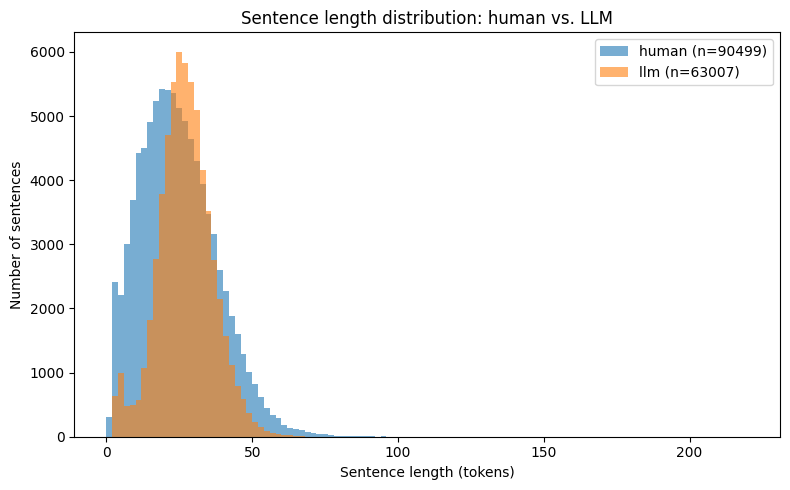

Saved /content/drive/MyDrive/IT469-NER-Project/results/data/sentence_length_hist.png


In [70]:
# Sentence-length histogram, human vs. LLM, saved to Drive.
if not PIPELINE_ALREADY_DONE:
    _human_lens = [r["n_tokens"] for r in records["human"]]
    _llm_lens = [r["n_tokens"] for r in records["llm"]]
    plt.figure(figsize=(8, 5))
    _bins = np.arange(0, max(max(_human_lens, default=1), max(_llm_lens, default=1)) + 5, 2)
    plt.hist(_human_lens, bins=_bins, alpha=0.6, label=f"human (n={len(_human_lens)})")
    plt.hist(_llm_lens, bins=_bins, alpha=0.6, label=f"llm (n={len(_llm_lens)})")
    plt.xlabel("Sentence length (tokens)")
    plt.ylabel("Number of sentences")
    plt.title("Sentence length distribution: human vs. LLM")
    plt.legend()
    plt.tight_layout()
    SENTENCE_LENGTH_HIST_PNG.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(SENTENCE_LENGTH_HIST_PNG, dpi=150)
    plt.show()
    print(f"Saved {SENTENCE_LENGTH_HIST_PNG}")


## 9. Size-matched human training set (step 13)

Within TRAIN and within each topic, take shuffled human sentences up to the LLM side's token count for that topic. Validation and test are never matched.


In [71]:
# Step 13: within TRAIN and within each topic, shuffle human sentences (seed 42) and take a token-matched
# prefix against that topic's LLM train token count.
if not PIPELINE_ALREADY_DONE:
    topics = sorted(df["topic"].unique())
    human_train = [r for r in records["human"] if r["split"] == "train"]
    llm_train = [r for r in records["llm"] if r["split"] == "train"]

    llm_tokens_by_topic = defaultdict(int)
    for r in llm_train:
        llm_tokens_by_topic[r["topic"]] += r["n_tokens"]

    human_train_by_topic = defaultdict(list)
    for r in human_train:
        human_train_by_topic[r["topic"]].append(r)

    rng = random.Random(SEED)  # separate seeded RNG so this step's randomness is independent and reproducible
    matched_records = []
    matched_stats_rows = []
    for topic in topics:
        target = llm_tokens_by_topic[topic]
        pool = sorted(human_train_by_topic[topic], key=lambda r: r["sent_id"])  # sort before shuffling
        rng.shuffle(pool)
        cum = 0
        kept = []
        for r in pool:
            if cum + r["n_tokens"] > target:
                break
            kept.append(r)
            cum += r["n_tokens"]
        matched_records.extend(kept)

        full_human_tokens = sum(r["n_tokens"] for r in human_train_by_topic[topic])
        matched_stats_rows.append({
            "topic": topic, "llm_tokens": target, "human_tokens_full": full_human_tokens,
            "human_tokens_matched": cum, "sentences_kept": len(kept),
            "pct_of_llm_tokens": round(cum / target * 100, 3) if target else 0.0,
        })

        assert cum <= target, f"{topic}: matched human tokens {cum} exceed the LLM target {target}"
        if not SMOKE_TEST:
            # 1% tolerance is only meaningful at full scale; a smoke sample's per-topic token counts are
            # small enough that a single sentence can swing the gap past 1%.
            gap_pct = (target - cum) / target * 100 if target else 0.0
            assert gap_pct <= 1.0, f"{topic}: matched human tokens are {gap_pct:.2f}% below the LLM target (> 1% tolerance)"

    matched_training_stats_df = pd.DataFrame(matched_stats_rows)
    matched_training_stats_df.to_csv(MATCHED_TRAINING_STATS_CSV, index=False)
    display(matched_training_stats_df)


,topic,llm_tokens,human_tokens_full,human_tokens_matched,sentences_kept,pct_of_llm_tokens
0,Celebrity,215097,285687,215090,10031,99.997
1,History and religion,210942,273005,210927,8284,99.993
2,Politics and government,219748,284624,219737,8539,99.995
3,Science and technology,227568,294459,227556,8864,99.995
4,Social culture and civil rights,230195,300049,230193,9376,99.999
5,Sports,239012,313495,239004,10300,99.997


In [72]:
# Save the matched subset as its own JSONL file.
if not PIPELINE_ALREADY_DONE:
    write_jsonl(matched_records, SENT_HUMAN_TRAIN_MATCHED_JSONL)
    logger.info(f"Saved {SENT_HUMAN_TRAIN_MATCHED_JSONL}: {len(matched_records)} sentences, "
                f"{sum(r['n_tokens'] for r in matched_records)} tokens")


2026-10-15 18:03:07,900 [INFO] Saved /content/drive/MyDrive/IT469-NER-Project/data/processed/sentences_human_train_matched.jsonl: 55394 sentences, 1342507 tokens
INFO:data_prep_full:Saved /content/drive/MyDrive/IT469-NER-Project/data/processed/sentences_human_train_matched.jsonl: 55394 sentences, 1342507 tokens


## 10. Summary

Finalize `articles_clean.csv`, show the full funnel/split/token picture in one place, and save `dataset_stats.json`. If everything was already built (Section 3), this loads it instead of recomputing.


In [73]:
# Finalize articles_clean.csv: attach per-article sentence/token counts and save.
if not PIPELINE_ALREADY_DONE:
    def _per_article_counts(records_side):
        counts = defaultdict(lambda: [0, 0])  # article_id -> [n_sents, n_tokens]
        for r in records_side:
            c = counts[r["article_id"]]
            c[0] += 1
            c[1] += r["n_tokens"]
        return counts

    _human_counts = _per_article_counts(records["human"])
    _llm_counts = _per_article_counts(records["llm"])
    df["human_n_sents"] = df["article_id"].map(lambda a: _human_counts[a][0])
    df["human_n_tokens"] = df["article_id"].map(lambda a: _human_counts[a][1])
    df["llm_n_sents"] = df["article_id"].map(lambda a: _llm_counts[a][0])
    df["llm_n_tokens"] = df["article_id"].map(lambda a: _llm_counts[a][1])

    articles_clean_df = df[[
        "article_id", "title", "agency", "topic", "group_id", "split", "human_text", "llm_text",
        "human_n_sents", "llm_n_sents", "human_n_tokens", "llm_n_tokens",
    ]]
    articles_clean_df.to_csv(ARTICLES_CLEAN_CSV, index=False)
    logger.info(f"Saved {ARTICLES_CLEAN_CSV}: {len(articles_clean_df)} articles")


2026-10-15 18:03:08,959 [INFO] Saved /content/drive/MyDrive/IT469-NER-Project/data/processed/articles_clean.csv: 2891 articles
INFO:data_prep_full:Saved /content/drive/MyDrive/IT469-NER-Project/data/processed/articles_clean.csv: 2891 articles


In [74]:
# Build and save dataset_stats.json; display the full summary.
if not PIPELINE_ALREADY_DONE:
    funnel = {
        "raw": cleaning_log["step1_missing_drop"]["before"],
        "after_missing_drop": cleaning_log["step1_missing_drop"]["after"],
    }
    if SMOKE_TEST:
        funnel["after_smoke_truncation"] = cleaning_log["smoke_truncation"]["after"]
    funnel["after_duplicate_titles"] = cleaning_log["step2_duplicate_title_drop"]["after"]
    funnel["after_empty_clean_drop"] = cleaning_log["empty_after_cleaning_drop"]["after"]
    funnel["final_after_near_duplicates"] = cleaning_log["step7_near_duplicate_drop"]["after"]

    dataset_stats = {
        "smoke_test": SMOKE_TEST,
        "generated_at": datetime.now(timezone.utc).isoformat(),
        "article_funnel": funnel,
        "split_by_topic": split_by_topic.to_dict(),
        "side_split_stats": side_split_stats_df.to_dict(orient="records"),
        "matched_training_stats": matched_training_stats_df.to_dict(orient="records"),
        "cleaning_log": cleaning_log,
        "related_groups": {
            "n_multi_article_groups": len(_multi_group_ids),
            "n_articles_in_groups": int(_group_sizes[_group_sizes > 1].sum()),
            "largest_group": int(_group_sizes.max()),
            "cross_topic_groups": _cross_topic_groups,
        },
    }
    save_json(dataset_stats, DATASET_STATS_JSON)
    logger.info(f"Saved {DATASET_STATS_JSON}")
else:
    dataset_stats = load_json(DATASET_STATS_JSON)
    funnel = dataset_stats["article_funnel"]
    split_by_topic = pd.DataFrame(dataset_stats["split_by_topic"])
    side_split_stats_df = pd.DataFrame(dataset_stats["side_split_stats"])
    matched_training_stats_df = pd.DataFrame(dataset_stats["matched_training_stats"])

print("Article funnel:")
for stage, count in funnel.items():
    print(f"  {stage}: {count}")

print("\nSplit by topic:")
display(split_by_topic)

print("\nSentences/tokens per side x split:")
display(side_split_stats_df)

print("\nMatched training set per topic:")
display(matched_training_stats_df)

if not dataset_stats["smoke_test"]:
    print("\nCleaning log highlights:")
    print(f"  LLM headlines removed: {dataset_stats['cleaning_log']['step5_llm_cleaning']['headlines_removed']} "
          f"({dataset_stats['cleaning_log']['step5_llm_cleaning']['headlines_removed_pct']}%)")
    print(f"  Human boilerplate lines removed: {dataset_stats['cleaning_log']['step6_human_boilerplate']}")
    print(f"  Near-duplicates dropped: {dataset_stats['cleaning_log']['step7_near_duplicate_drop']['dropped']}")
    print(f"  Related groups: {dataset_stats['related_groups']}")


2026-10-15 18:03:08,988 [INFO] Saved /content/drive/MyDrive/IT469-NER-Project/results/data/dataset_stats.json
INFO:data_prep_full:Saved /content/drive/MyDrive/IT469-NER-Project/results/data/dataset_stats.json


Article funnel:
  raw: 3000
  after_missing_drop: 2954
  after_duplicate_titles: 2895
  after_empty_clean_drop: 2895
  final_after_near_duplicates: 2891

Split by topic:


split,test,train,validation
topic,,,
Celebrity,52,377,44
History and religion,64,368,50
Politics and government,42,387,52
Science and technology,36,400,49
Social culture and civil rights,52,385,47
Sports,44,398,44



Sentences/tokens per side x split:


,side,split,n_sentences,n_tokens,avg_len,median_len,max_len,n_long
0,human,train,72307,1751319,24.22,23.0,127,9
1,human,validation,9060,219427,24.22,23.0,115,2
2,human,test,9132,217464,23.81,22.0,217,2
3,llm,train,50521,1342562,26.57,26.0,85,0
4,llm,validation,6221,168119,27.02,27.0,70,0
5,llm,test,6265,167623,26.76,27.0,70,0



Matched training set per topic:


,topic,llm_tokens,human_tokens_full,human_tokens_matched,sentences_kept,pct_of_llm_tokens
0,Celebrity,215097,285687,215090,10031,99.997
1,History and religion,210942,273005,210927,8284,99.993
2,Politics and government,219748,284624,219737,8539,99.995
3,Science and technology,227568,294459,227556,8864,99.995
4,Social culture and civil rights,230195,300049,230193,9376,99.999
5,Sports,239012,313495,239004,10300,99.997



Cleaning log highlights:
  LLM headlines removed: 2873 (99.2%)
  Human boilerplate lines removed: {'separator': 752, 'contributed_to_report': 165, 'follow_social': 203, 'photo_credit': 20, 'byline': 19, 'web_leftover': 40, 'template_placeholder': 21}
  Near-duplicates dropped: 4
  Related groups: {'n_multi_article_groups': 34, 'n_articles_in_groups': 70, 'largest_group': 3, 'cross_topic_groups': []}


## 11. References

[1] N. Ayoobi, S. Shahriar, and A. Mukherjee, "Seeing through AI's lens: Enhancing human skepticism
towards LLM-generated fake news," in Proc. 35th ACM Conf. Hypertext and Social Media (HT), 2024.
doi:10.1145/3648188.3675136

[2] E. F. Tjong Kim Sang and F. De Meulder, "Introduction to the CoNLL-2003 shared task:
Language-independent named entity recognition," CoNLL 2003, pp. 142-147. arXiv:cs/0306050

[3] K. Lee, D. Ippolito, A. Nystrom, C. Zhang, D. Eck, C. Callison-Burch, and N. Carlini,
"Deduplicating training data makes language models better," ACL 2022.
https://aclanthology.org/2022.acl-long.577

[4] A. Sogaard, S. Ebert, J. Bastings, and K. Filippova, "We need to talk about random splits," EACL 2021.
https://aclanthology.org/2021.eacl-main.156

[5] P. Lewis, P. Stenetorp, and S. Riedel, "Question and answer test-train overlap in open-domain
question answering datasets," EACL 2021. https://aclanthology.org/2021.eacl-main.86

[6] M. Banko and E. Brill, "Scaling to very very large corpora for natural language disambiguation,"
ACL 2001. https://aclanthology.org/P01-1005

[7] D. Ashok and J. May, "A little human data goes a long way," arXiv:2410.13098, 2024.

[8] T. Kiss and J. Strunk, "Unsupervised multilingual sentence boundary detection," Computational
Linguistics, vol. 32, no. 4, pp. 485-525, 2006.

[9] S. Bird, E. Klein, and E. Loper, Natural Language Processing with Python. O'Reilly Media, 2009. (NLTK)

[10] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," JMLR, vol. 12, pp. 2825-2830, 2011.

**Resource links**

- LLM-generated News dataset repository: https://github.com/navid-aub/News-Dataset
- NLTK: https://www.nltk.org
- scikit-learn `StratifiedGroupKFold` documentation:
  https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html
